# Modulación LoRa (FSCM)

Modelo en Python de la modulación LoRa basado en el análisis de
L. Vangelista, ["Frequency Shift Chirp Modulation: The LoRa Modulation"](https://doi.org/10.1109/LSP.2017.2762960),
*IEEE Signal Processing Letters*, vol. 24, no. 12, pp. 1818–1821, dic. 2017.

| Autor                | Email                             |
|----------------------|-----------------------------------|
| Badenes, Tomás       | tomasbadenes@mi.unc.edu.ar        |
| Pineda, Juan Ignacio | juan.ignacio.pineda@mi.unc.edu.ar |
| Doniquian, Pedro     | pedoniquian@mi.unc.edu.ar         |

## Modelo del sistema

*TODO(b-Tomas): diagrama de bloques*

In [1]:
import numpy as np

from lora import LoRaParams, channel, detection, metrics, plots, rng, rx, seed, simulation, tx

# Semilla global: las corridas son reproducibles
seed(0)

## Transmisión

El módulo transmisor se compone de dos partes: el codificador y el conformador de onda.

### Codificador

Se considera como objetivo transmitir y recibir un conjunto de bits. Para esto, se debe convertir el conjunto de bits en símbolos.

El bloque de parámetros ya define los símbolos a enviar en la lista `symbols`, por lo que primero se retrocederá un paso para convetirlos en el conjunto de bits a enviar. Luego, `tx.encoder()` tomará el conjunto de bits y los convertirá en símbolos.

Cada símbolo se genera con un vector $w(nT_s)$ de $SF$ bits de acuerdo a Ec. 1:

$$
s(nT_s) = \sum_{h=0}^{SF-1} w(nT_s)_h \cdot 2^h
$$

$w_0$ es el bit menos significativo. El flujo de bits se corta en grupos de $SF$ bits, un grupo por símbolo.

### Conformador de onda

Dado el vector de símbolos $s(nT_s)$, el conformador de onda genera la señal modulada de acuerdo a Ec. 2 para cada símbolo $n$ y cada chip $k = 0, \dots, 2^{SF}-1$:

$$
c(nT_s + kT) = \frac{1}{\sqrt{2^{SF}}}\, e^{\,j2\pi \left[(s(nT_s) + k) \bmod 2^{SF}\right] kT \frac{B}{2^{SF}}}
$$

El resultado $c(nT_s + kT)$ es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

#### Análisis de la señal modulada

Antes de continuar con la transmisión, se analiza la forma y comportamiento de la señal modulada en tiempo y en frecuencia en una configuración con *Spreading Factor* de 7.

In [2]:
p = LoRaParams(SF=7, B=125e3)  # Ancho de banda de 125 kHz
symbols = np.array([0, 32, 80])

c = tx.modulator(symbols, p)

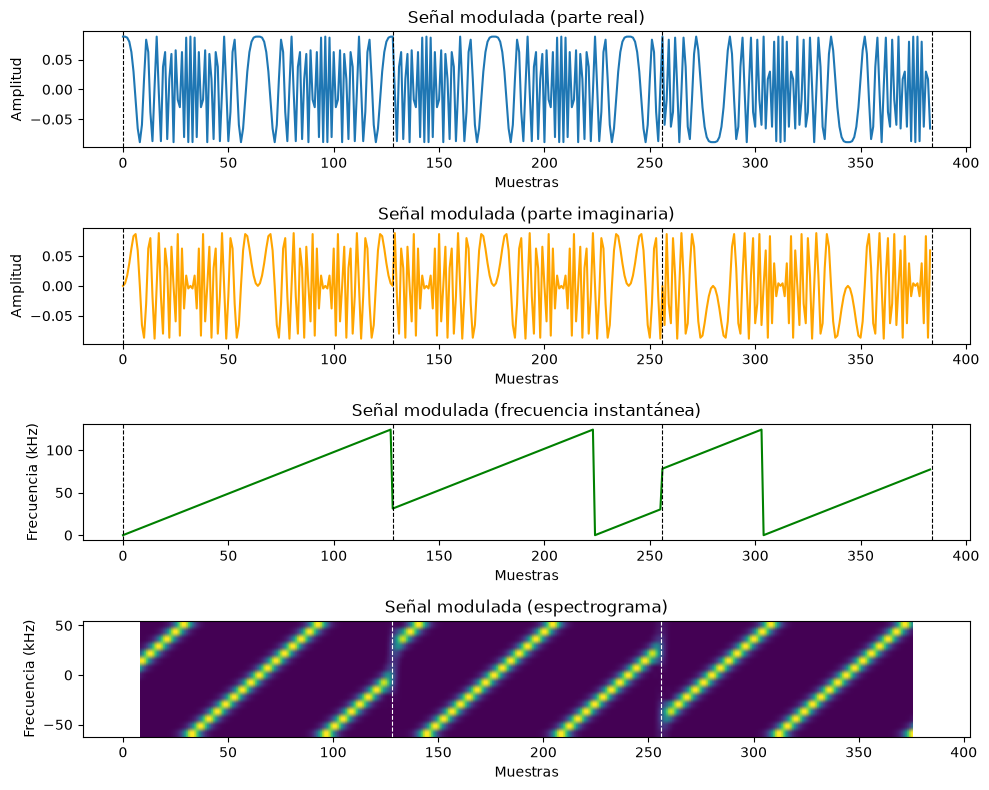

In [3]:
plots.modulated_signal(c, symbols, p);

**Dominio del tiempo**:
- La señal es una exponencial compleja de frecuencia variable, conocida como *chirp*.
- La parte real es una onda cosenoidal de frecuencia creciente, mientras que la parte imaginaria es una onda senoide de frecuencia creciente.

**Frecuencia instantánea**:
- El gráfico muestra la frecuencia instantánea de la señal de la Ec. 2. con fines pedagógicos.
- De acuerdo con lo que se puede ver en las ondas de la parte real e imaginaria, la frecuencia instantánea es una función lineal del tiempo, que aumenta de 0 a $B$ en el intervalo de tiempo $T_s$.
- La frecuencia instantánea inicial para cada símbolo es distinta de acuerdo a $f_0 = \frac{B}{2^{SF}} s(nT_s)$.

**Espectrograma:**
- Muestra la frecuencia real de $c$.

## Recepción

El módulo receptor se compone de un demodulador y un decodificador.

### Demodulación

Se conoce a esta etapa como *n-Tuple former* o conformador de tuplas, y genera símbolos a partir de la señal recibida, la cual es un vector complejo unidimensional de $2^{SF}$ chips por cada símbolo $n$.

Se analizará primero demodulando la señal modulada, y luego sumándole ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

El proceso de demodulación de forma computacionalmente eficiente se describe en Ec. 16 como la proyección de la señal recibida $r(nT_s + kT)$ sobre un conjunto de *chirps* ortogonales $c|_{q}$:

$$
\langle r, c|_{s=q} \rangle = \sum_{k=0}^{2^{SF}-1} r(nT_s + kT)\, e^{-j2\pi \frac{k^2}{2^{SF}}} \cdot \frac{1}{\sqrt{2^{SF}}}\, e^{-j2\pi \frac{qk}{2^{SF}}}
$$

Se puede interpretar como la correlación entre la señal recibida y todos los *chirps* posibles, siendo el *chirp* que maximiza la proyección el símbolo recibido.

El término $e^{-j2\pi \frac{k^2}{2^{SF}}}$ se conoce como *down-chirp*. El resultado $d(nT_s + kT) = r(nT_s + kT) \cdot e^{-j2\pi \frac{k^2}{2^{SF}}}$ es una exponencial compleja de frecuencia constante igual a la frecuencia inicial del símbolo recibido. Se utiliza la transformada rápida de Fourier (FFT).

Luego, la transformada de Fourier de $d(nT_s + kT)$ resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.


#### Visualización del proceso de decisión

Para cada símbolo recibido se obtiene la frecuencia inicial del *chirp* recibido mediante el *down-chirp* y la FFT. La transformada de Fourier de $d(nT_s + kT)$ (una exponencial compleja de frecuencia constante) resultará en un impulso desplazado en el índice de la frecuencia correspondiente a la frecuencia del símbolo recibido.

Mas adelante se analizará la decisión en un canal ruidoso.

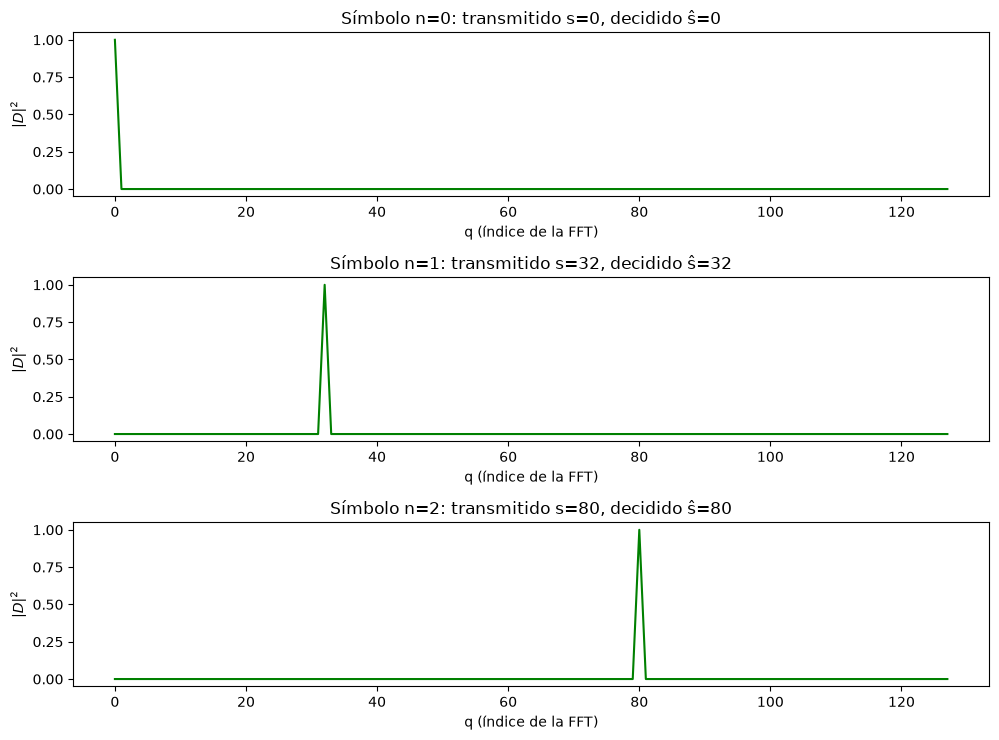

In [4]:
# Salida de la FFT del demodulador antes de decidir
D = rx.dechirp_fft(c, p)
symbols_rx = rx.demodulator(c, p)

plots.fft_decision(D, symbols, symbols_rx);

### Decodificación

Se descompone cada símbolo en un arreglo de $SF$ bits de acuerdo a Ec. 1.

## Cálculo del Bit Error Rate (BER)

El BER se calcula comparando el conjunto de bits transmitidos con el conjunto de bits recibidos. Se considera un bit erróneo si el bit recibido es distinto al bit transmitido.

Ya que aún no hemos introducido ruido en el canal, esperamos que el BER sea 0.

In [5]:
# Simular una transmisión completa de 100 símbolos aleatorios
bits_tx = rng.integers(0, 2, size=p.SF * 100)
bits_rx = rx.decoder(rx.demodulator(tx.modulator(tx.encoder(bits_tx, p), p), p), p)
print(f"Bit Error Rate (BER): {metrics.BER(bits_tx, bits_rx):.4f}")

# En caso de corromper un bit:
bits_rx[0] ^= 1  # bit flip
print(f"Bit Error Rate (BER) con un bit corrupto: {metrics.BER(bits_tx, bits_rx):.4f}")

Bit Error Rate (BER): 0.0000
Bit Error Rate (BER) con un bit corrupto: 0.0014


## Potencia de la señal modulada

In [6]:
for SF in [7, 2]:
    q = LoRaParams(SF=SF, B=125e3)
    P = metrics.power(tx.modulator(np.array([0]), q))
    print(f"Potencia de la señal modulada con SF={SF}, B={q.B / 1e3:.0f} kHz: {P:.4f}")

Potencia de la señal modulada con SF=7, B=125 kHz: 0.0078
Potencia de la señal modulada con SF=2, B=125 kHz: 0.2500


## Modelo de canal ruidoso

El canal dos distorsiones significativas sobre la señal transmitida $c(nT_s + kT)$: atenuación y desplazamiento. Esto se puede modelar con la respuesta al impulso del canal como sistema SLIT.

Luego, a la señal distorsionada se le suma ruido blanco gaussiano aditivo (AWGN) para simular la transmisión por un canal ruidoso.

In [7]:
# Transmisión de 100 símbolos aleatorios por un canal plano
SNR_dB = -10
ber = simulation.transmission_ber(p, SNR_dB, channel.FLAT)
print(f"Bit Error Rate (BER) con SNR={SNR_dB}dB: {ber:.4f}")

Bit Error Rate (BER) con SNR=-10dB: 0.0014


### Detección con ruido en un canal plano

Se repite la simulación de la transmisión y recepción de símbolos, pero esta vez se introduce ruido blanco gaussiano aditivo (AWGN) en el canal.

El canal es plano, es decir, respuesta en frecuencia constante.

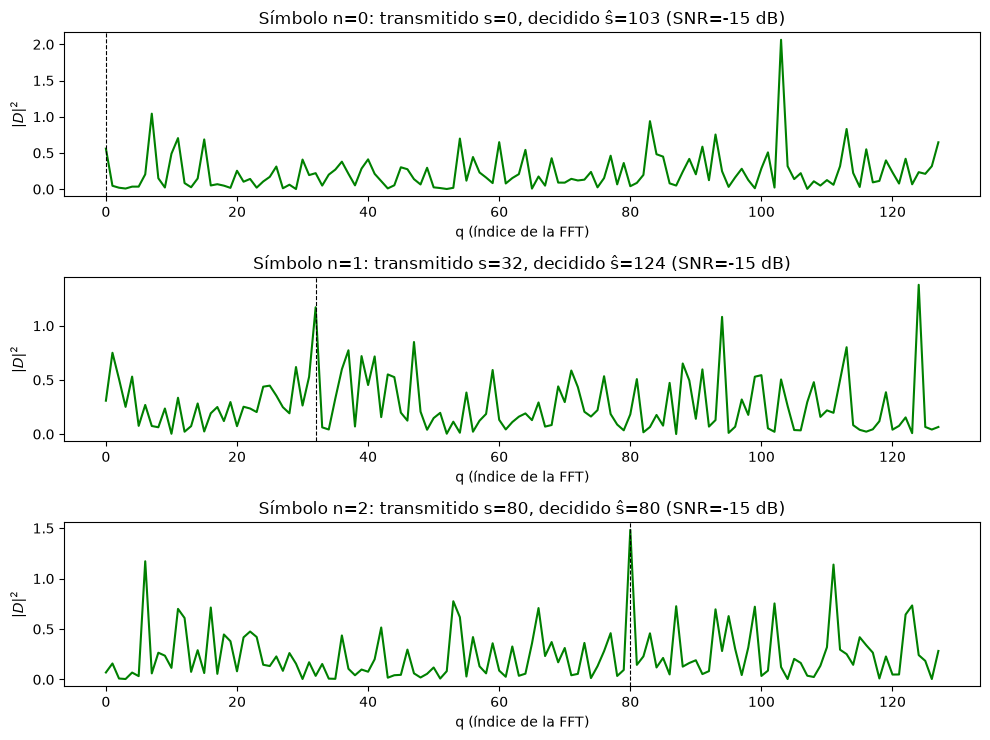

In [8]:
# Probar distintos SNR para ver cuándo empieza a fallar la decisión
SNR_dB = -15
c = tx.modulator(symbols, p)
r = channel.system(c, channel.FLAT, channel.noise_from_SNR(c, SNR_dB))

plots.fft_decision(rx.dechirp_fft(r, p), symbols, rx.demodulator(r, p), SNR_dB);

### Detección con ruido en un canal selectivo en frecuencia

Un canal no plano es selectivo en frecuencia. La respuesta al impulso del sistema usado para modelar un canal multicaminos es:

$$
h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]
$$



### Performance de detección

Se analiza el BER vs SNR para el sistema simulado, el cual corresponde a la curva "Flat FSCM" de Fig. 1.

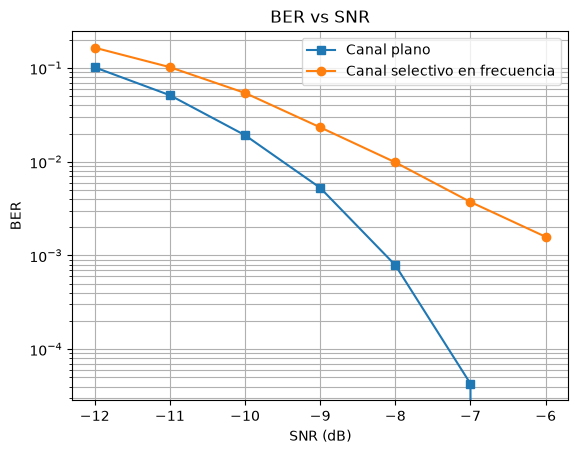

In [9]:
SNRs_dB = np.arange(-12.0, -5.0)  # -12 a -6 dB
simulations = 500  # Transmisiones de 100 símbolos por SNR

bers = {
    "Canal plano": simulation.ber_vs_snr(p, SNRs_dB, channel.FLAT, simulations),
    "Canal selectivo en frecuencia": simulation.ber_vs_snr(
        p, SNRs_dB, channel.FREQ_SELECTIVE, simulations
    ),
}
plots.ber_vs_snr(SNRs_dB, bers);

## Detección de una trama

En esta sección se analiza el problema de detectar una trama en un canal ruidoso del lado del receptor: decidir si llegó una trama y en qué muestra empieza (sincronización). La trama es un preámbulo de 8 *up-chirps* (símbolos 0) y 2.25 *down-chirps*, seguido del *payload*. Antes de la trama el receptor solo recibe ruido, y no sabe cuándo empieza.

Se plantean tres métodos:

1. **Correlación con el preámbulo completo** (tiempo): filtro adaptado con los 8 *up-chirps*, integración coherente.
2. **Búsqueda de 8 picos** (tiempo): correlación móvil con un solo *up-chirp*, sumando la energía de 8 picos separados un símbolo. Integración no coherente.
3. **Demodulación del preámbulo** (frecuencia): se demodula cada ventana y se cuentan las decididas como símbolo 0.

Para cada método se presenta el estadístico y su umbral de Neyman-Pearson, la validación en un canal ideal y la performance en un canal selectivo en frecuencia. Al final se comparan los tres métodos: detección del inicio, curva ROC y *Frame Error Rate* (FER).

### Escenario y herramientas comunes

**Parámetros**: desde acá se usa $SF = 8$ y un *payload* de 10 símbolos. Con $SF = 7$, a $-10$ dB la demodulación falla en el 4 % de los símbolos y se pierde casi la mitad de las tramas, sin importar el detector. Con $SF = 8$ cada símbolo dura el doble de muestras: a igual SNR por muestra tiene 3 dB más de energía, y el FER a $-10$ dB baja a $\approx 2 \cdot 10^{-3}$. La variación del FER con el SF y con el largo de la trama se estudia al final.

**Escenario de validación**: el receptor escucha 5 símbolos de solo ruido antes de la trama. La validación de cada método se hace en un canal ideal (plano, $h[n] = \delta[n]$, solo AWGN) a $-10$ dB. La performance se evalúa además en el canal selectivo en frecuencia de la sección de BER, $h[n] = \sqrt{0.8}\,\delta[n] + \sqrt{0.2}\,\delta[n-1]$.

**Umbral**: los tres métodos fijan el umbral con el criterio de Neyman-Pearson para la misma probabilidad de falsa alarma por símbolo, $P_{FA}$. Su valor no se elige a mano: sale de la tasa de falsas alarmas que tolera el receptor. Cada falsa alarma hace que el receptor intente demodular una trama que no existe: gasta energía y, mientras tanto, puede perder una trama real. El receptor evalúa $B / 2^{SF}$ símbolos por segundo ($\approx 488$ con $SF = 8$ y $B = 125$ kHz), así que para tolerar $R_{FA}$ falsas alarmas por segundo:

$$
P_{FA} = R_{FA}\, \frac{2^{SF}}{B}
$$

Se toma una falsa alarma por minuto, $R_{FA} = 1/60\ \text{s}^{-1}$, de donde $P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo. Como referencia, $P_{FA} = 10^{-3}$ daría una falsa alarma cada 2 segundos. Se asume que el receptor conoce la potencia del ruido $\sigma^2$; en la práctica se estima mientras no hay señal.

**Inicio de la trama**: las posiciones anteriores al inicio ya se superponen con parte del preámbulo, así que el primer cruce del umbral suele llegar antes de tiempo. `detect_start` declara $H_1$ en el primer cruce y estima el inicio como el máximo del estadístico en el largo del preámbulo siguiente. En el escenario el silencio dura 5 símbolos, menos que esa búsqueda: una falsa alarma en el silencio queda "rescatada" por el preámbulo que llega después. Por eso las falsas alarmas se validan aparte, sobre una señal de solo ruido (ver la comparación de los métodos).

**Métricas**:

- **Inicio correcto**: fracción de tramas cuyo inicio se detecta en la posición exacta. Una detección temprana (falsa alarma), una tardía o la no detección (*miss*) cuentan como error.
- **Frame Error Rate (FER)**: el BER evalúa cada bit por separado, pero en un sistema que transmite tramas la unidad útil es la trama: si un solo bit del *payload* es incorrecto la trama se descarta (en la práctica lo detecta un CRC), y si no se detecta el preámbulo se pierde la trama entera. Mide el sistema completo, detección y demodulación juntas: no sirve para comparar los detectores entre sí (ver la sección de FER).

$$
FER = \frac{\text{tramas con error}}{\text{tramas enviadas}}
$$

Una trama tiene error si ocurre cualquiera de estos eventos:

- **Miss**: no se detecta el preámbulo.
- **Inicio incorrecto** (falsa alarma, detección temprana o tardía): el *payload* se demodula con ventanas que no corresponden a sus símbolos.
- **Error de demodulación**: el inicio es correcto, pero algún símbolo del *payload* se decide mal.

Una vez detectada la muestra de inicio $\hat{k}$, el receptor conoce la estructura del preámbulo, por lo que el *payload* empieza $8 + 2.25$ símbolos después: en la muestra $\hat{k} + 10.25 \cdot 2^{SF}$. Si el inicio es correcto y los $N$ símbolos del *payload* se deciden de forma independiente con probabilidad de error de símbolo $SER$:

$$
FER = 1 - P(\text{inicio correcto})\,(1 - SER)^N
$$

El FER crece con el largo de la trama: aunque el BER sea bajo, una trama larga tiene más oportunidades de tener algún error. Para separar el aporte de la detección del de la demodulación, se compara cada detector con una detección ideal en la que el receptor conoce el inicio de la trama.

Cada método se resume en una función `detect(r, p, noise_power, P_FA)` que devuelve la muestra de inicio detectada, o `None`. `frame_rates` simula tramas con cualquiera de ellas y estima ambas métricas.

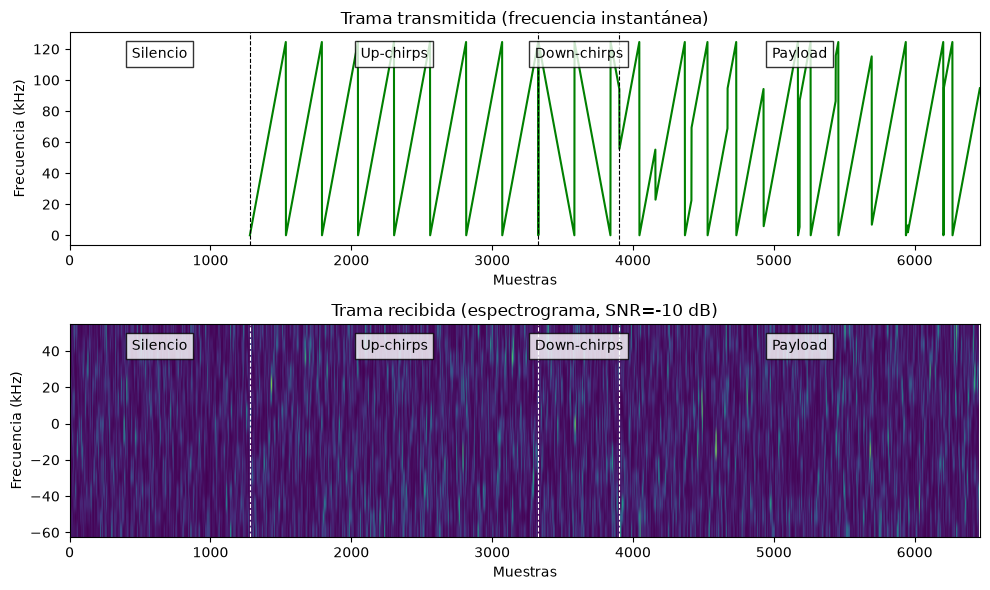

In [10]:
# Escenario para analizar las estrategias de detección
p = LoRaParams(SF=8, B=125e3)
num_symbols = 10  # Símbolos del payload
SNR_dB = -10
gap = 5  # Símbolos de silencio antes de la trama: desconocido para el receptor
symbols_tx = rng.integers(0, p.M, size=num_symbols)

r = channel.transmit_frame(symbols_tx, gap, p, SNR_dB, channel.FLAT)
r_clean = channel.transmit_frame(symbols_tx, gap, p, 100, channel.FLAT)  # Sin ruido apreciable

# Potencia del ruido por muestra (sigma^2). Se asume que el receptor la conoce: en la práctica se
# estima mientras no hay señal
noise_power = channel.noise_power(p, SNR_dB)

plots.frame_structure(r, symbols_tx, gap, p, SNR_dB);

In [11]:
# Parámetros comunes a la validación y la performance de los tres métodos
R_FA = 1 / 60  # Tasa de falsas alarmas tolerable: una por minuto
P_FA = R_FA * p.Ts  # Probabilidad de falsa alarma por símbolo
SNRs_rates_dB = np.arange(-24.0, -3.0, 1.0)  # -24 a -4 dB
simulations = 300  # Tramas simuladas por SNR

# Inicio correcto de cada método ("full", "peaks", "freq"), en cada canal
start_flat, start_sel = {}, {}

### Detección en el tiempo: correlación móvil con un up-chirp

En el tiempo el receptor no necesita sincronía de símbolo: desliza una plantilla conocida sobre la señal recibida, muestra a muestra, y busca dónde se parece más. La muestra $k$ donde se decide $H_1$ es a la vez la detección y la sincronización: es donde empieza la trama.

Para cada muestra $k$ se plantea un test de hipótesis binario:

- $H_0$: el preámbulo no empieza en la muestra $k$. Se recibe solo ruido, u otra parte de la trama.
- $H_1$: el preámbulo empieza en la muestra $k$: $r_k = p + w$, donde $r_k$ son las muestras recibidas a partir de $k$, $p$ son los 8 *up-chirps* del preámbulo (conocidos) y $w$ es ruido gaussiano i.i.d.

Los dos métodos parten de la correlación móvil de la señal recibida con un solo *up-chirp* (símbolo 0):

$$
y[k] = \langle r_k, c|_{s=0} \rangle = \sum_{i=0}^{2^{SF}-1} r(kT + iT)\, c^*(iT)|_{s=0}
$$

Dentro del preámbulo, $|y[k]|^2$ es máxima cuando la plantilla queda alineada con un *up-chirp*, y nula con cualquier otro desplazamiento: un *up-chirp* desplazado en el tiempo es un *up-chirp* con un corrimiento de frecuencia, ortogonal al original.

Los picos aparecen cada $2^{SF}/2$ muestras y no cada $2^{SF}$. Con la fase de la Ec. 2, $2\pi k^2 / 2^{SF}$ para el símbolo 0, la frecuencia instantánea real (la derivada de la fase) barre de 0 a $2B$ y, muestreada a $B$, se repliega: cada *up-chirp* son dos copias de un *chirp* de $2^{SF}/2$ muestras, y el preámbulo produce 16 picos.

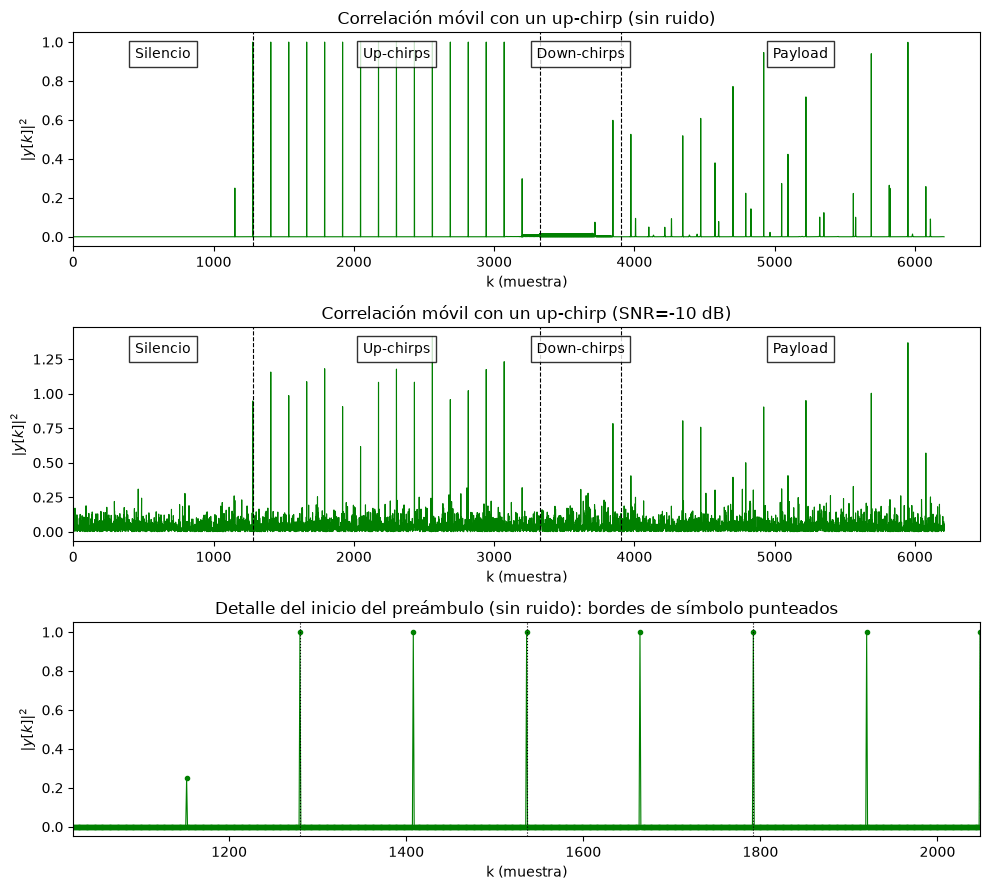

In [12]:
# Correlación móvil con un up-chirp sobre la trama del escenario, sin ruido y con ruido
y_clean = detection.upchirp_correlation(r_clean, p)
y = detection.upchirp_correlation(r, p)

plots.upchirp_correlation(y_clean, y, gap, p, SNR_dB);

**Observaciones**:
- Sin ruido se ve la estructura de la trama: picos de altura 1 cada $2^{SF}/2$ muestras durante los *up-chirps*, nada en el silencio ni en los *down-chirps*, y picos aislados en el *payload* (donde un símbolo, o una mezcla de dos símbolos consecutivos, se parece a un *up-chirp*).
- Con ruido los picos del preámbulo siguen sobresaliendo, pero el ruido también produce picos: decidir con uno solo daría muchas falsas alarmas. Los dos métodos en el tiempo combinan los 8 picos que deja el preámbulo, separados un símbolo: uno en forma coherente y otro no coherente.

### Detección en el tiempo: correlación con el preámbulo completo

La plantilla es el preámbulo completo de 8 *up-chirps*, $p$. Es el problema de detectar una señal conocida en ruido gaussiano: el test de razón de verosimilitud se reduce a correlar la señal recibida con la señal conocida (filtro adaptado) y comparar con un umbral. Como la fase de la señal recibida es desconocida, se compara el módulo al cuadrado:

$$
T[k] = \left| \langle r_k, p \rangle \right|^2 = \left| \sum_{n=0}^{7} y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta
$$

Como $p$ son *up-chirps* repetidos, correlar con $p$ es sumar los 8 picos de $y[k]$ separados un símbolo. La suma es coherente (antes del módulo): las amplitudes de la señal se suman en fase (potencia $\times 64$) mientras que las potencias del ruido se suman ($\times 8$), una ganancia de $10\log_{10} 8 \approx 9$ dB respecto de un solo pico. A cambio, necesita que la fase de la señal se mantenga durante los 8 símbolos: un corrimiento de frecuencia entre transmisor y receptor rota los picos y la suma deja de ser coherente.

**Umbral (Neyman-Pearson)**: no se conocen las probabilidades *a priori* de $H_0$ y $H_1$, por lo que se fija la probabilidad de falsa alarma $P_{FA}$ tolerable. Cada *chirp* tiene energía 1, así que bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$ (potencia del ruido por muestra), la suma de 8 tiene varianza $8\sigma^2$ y $T[k]$ tiene distribución exponencial de media $8\sigma^2$:

$$
P_{FA} = P(T[k] > \eta \mid H_0) = e^{-\eta / 8\sigma^2} \quad\Rightarrow\quad \eta = -8\sigma^2 \ln P_{FA}
$$

Se asume que el receptor conoce $\sigma^2$; en la práctica se estima mientras no hay señal. $P_{FA}$ es por muestra: el test se repite en las $2^{SF}$ muestras de cada símbolo. Para tener la misma tasa de falsas alarmas que un test por símbolo con $P_{FA}$, se usa $P_{FA} / 2^{SF}$ en cada muestra.

**Inicio de la trama**: alrededor del inicio, $T[k]$ es un peine. Cada $2^{SF}/2$ muestras la plantilla vuelve a alinearse con parte del preámbulo: con $j$ medios *chirps* fuera, $T \approx 64\,(1 - j/16)^2$. El primer cruce del umbral suele ser uno de estos picos laterales, antes del inicio, así que el inicio se estima como el máximo de $T[k]$ en los 8 símbolos ($8 \cdot 2^{SF}$ muestras) siguientes al primer cruce.

Los *down-chirps* del preámbulo no intervienen en la detección.

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests en `tests/`). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

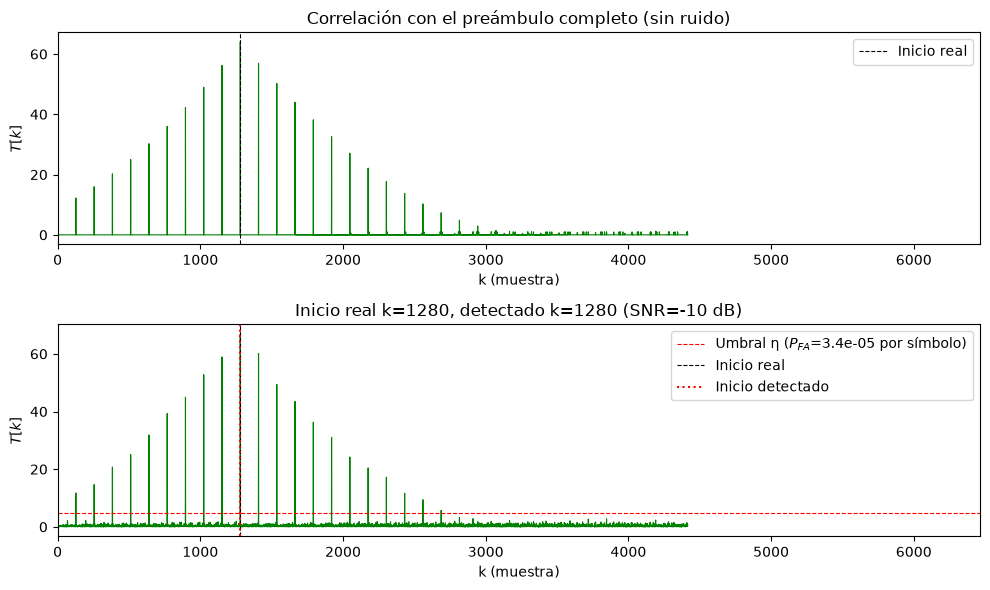

In [13]:
# Correlación con el preámbulo completo sobre el escenario
eta = detection.threshold("full", p, noise_power, P_FA)
T = detection.preamble_correlation(r, p)
T_clean = detection.preamble_correlation(r_clean, p)
start = detection.detect_start(T, eta, p.n_upchirps * p.M)

plots.full_preamble_detection(T_clean, T, eta, start, gap, p, P_FA, SNR_dB);

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia.

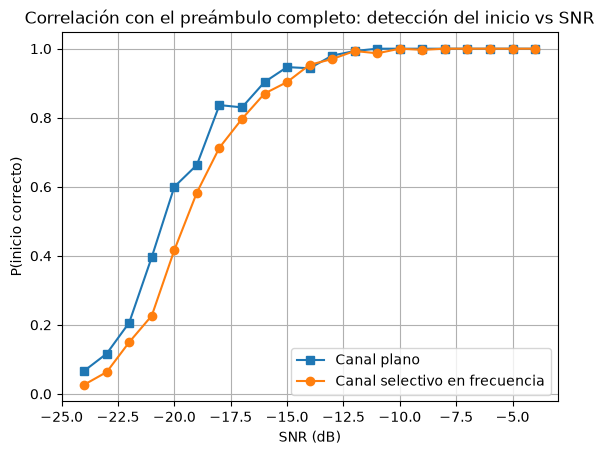

In [14]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
start_flat["full"], _ = simulation.frame_rates(
    detection.detect_full,
    SNRs_rates_dB,
    channel.FLAT,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)
start_sel["full"], _ = simulation.frame_rates(
    detection.detect_full,
    SNRs_rates_dB,
    channel.FREQ_SELECTIVE,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)

plots.start_vs_snr(
    SNRs_rates_dB,
    start_flat["full"],
    start_sel["full"],
    "Correlación con el preámbulo completo: detección del inicio vs SNR",
);

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-20.5$ dB, y en todas desde $-11$ dB.
- El canal selectivo cuesta $\approx 1$ dB. La plantilla solo captura el camino principal, que lleva el 80 % de la energía ($10\log_{10} 0.8 \approx -1$ dB). El eco produce otro pico una muestra después, más débil, que no confunde la localización.

### Detección en el tiempo: búsqueda de 8 picos

En lugar de un pico de la correlación con el preámbulo completo, se buscan los 8 picos que deja el preámbulo en la correlación móvil con un solo *up-chirp*: 8 picos seguidos, separados un tiempo de símbolo ($2^{SF}$ muestras). El estadístico suma la energía de los 8 picos candidatos a partir de la muestra $k$:

$$
S[k] = \sum_{n=0}^{7} \left| y[k + n\,2^{SF}] \right|^2 \;\underset{H_0}{\overset{H_1}{\gtrless}}\; \eta_S
$$

La diferencia con $T[k]$ es dónde se toma el módulo. $T[k]$ suma los picos y después toma el módulo (integración coherente); $S[k]$ toma el módulo de cada pico y después suma (integración no coherente). Al sumar energías se descarta la fase de cada pico: el método tolera que la fase cambie entre símbolos, pero el ruido de cada pico suma su energía en lugar de promediarse con el de los demás, por lo que se espera que necesite más SNR que $T[k]$.

Los picos intermedios, a $2^{SF}/2$ muestras, no se usan. Con picos separados un símbolo las 8 correlaciones usan muestras disjuntas, y bajo $H_0$ son independientes.

**Umbral (Neyman-Pearson)**: bajo $H_0$ cada $y[k + n\,2^{SF}]$ es gaussiano complejo de varianza $\sigma^2$, así que $|y|^2$ es exponencial de media $\sigma^2$. Los 8 son independientes, por lo que $S[k]$ tiene distribución Gamma de orden 8 (Erlang) y escala $\sigma^2$, con cola en forma cerrada:

$$
P_{FA} = P(S[k] > \eta_S \mid H_0) = e^{-\eta_S/\sigma^2} \sum_{i=0}^{7} \frac{(\eta_S/\sigma^2)^i}{i!}
$$

$\eta_S$ no se puede despejar, pero la cola es decreciente en $\eta_S$: se busca por bisección. Igual que en $T[k]$, se usa $P_{FA} / 2^{SF}$ por muestra.

**Inicio de la trama**: $S[k]$ también es un peine alrededor del inicio. Con $j$ medios *chirps* fuera del preámbulo, los 8 picos candidatos caen en picos intermedios, o fuera del preámbulo: $S \approx 8 - j/2$. Los picos laterales de $S[k]$ son más altos, relativos al principal, que los de $T[k]$, y el inicio se estima de la misma forma: el máximo en los 8 símbolos siguientes al primer cruce.

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests en `tests/`). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

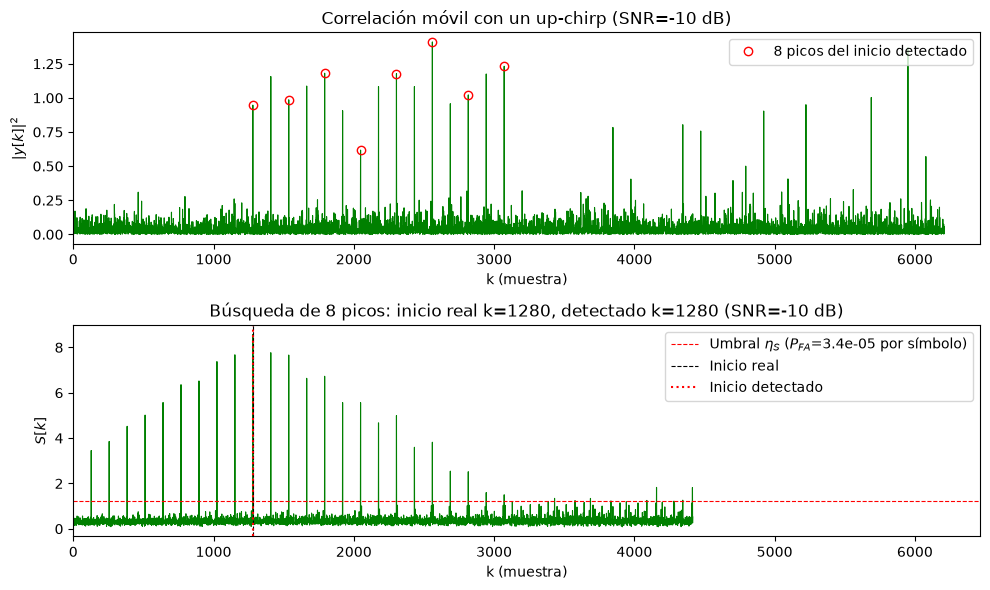

In [15]:
# Búsqueda de 8 picos sobre el escenario
eta_S = detection.threshold("peaks", p, noise_power, P_FA)
S = detection.peaks_statistic(r, p)
start = detection.detect_start(S, eta_S, p.n_upchirps * p.M)

plots.peaks_detection(y, S, eta_S, start, gap, p, P_FA, SNR_dB);

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia.

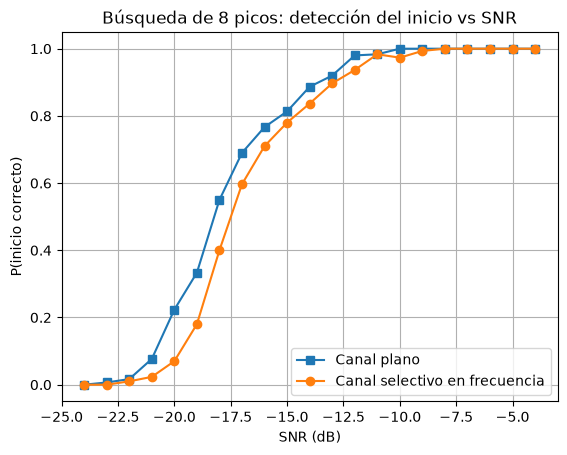

In [16]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
start_flat["peaks"], _ = simulation.frame_rates(
    detection.detect_peaks,
    SNRs_rates_dB,
    channel.FLAT,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)
start_sel["peaks"], _ = simulation.frame_rates(
    detection.detect_peaks,
    SNRs_rates_dB,
    channel.FREQ_SELECTIVE,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)

plots.start_vs_snr(
    SNRs_rates_dB,
    start_flat["peaks"],
    start_sel["peaks"],
    "Búsqueda de 8 picos: detección del inicio vs SNR",
);

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-18.5$ dB, unos 2 dB peor que la correlación con el preámbulo completo. Es la pérdida de la integración no coherente: el ruido de cada pico suma su energía.
- La localización es más débil: con medio símbolo de error los 8 picos candidatos caen sobre los picos intermedios y $S \approx 7.25$, contra 8 en el inicio. Cuando la detección falla cerca del inicio, suele ser por $2^{SF}/2$ muestras (se puede ver repitiendo el escenario de validación).
- El canal selectivo cuesta $\approx 1$ dB, por la misma razón que en la correlación con el preámbulo completo.

### Detección en frecuencia: demodulación del preámbulo

A diferencia de la detección en el tiempo, se asume sincronía de símbolo: el receptor divide la señal recibida en ventanas de $2^{SF}$ muestras alineadas con los bordes de los símbolos, y lo que no conoce es en qué ventana $m$ empieza la trama. Las hipótesis son las mismas que en el tiempo, por ventana en lugar de por muestra.

La estrategia en frecuencia reutiliza el demodulador (Ec. 16): cada ventana se multiplica por el *down-chirp* y se calcula su FFT. Durante el preámbulo cada ventana es un *up-chirp* de símbolo 0, por lo que el pico de la FFT aparece en el bin $q = 0$.

Mirar solo el bin 0 no aporta nada nuevo: por definición de la DFT, $D_n[0]$ es la suma de las muestras de la ventana multiplicadas por el *down-chirp*, es decir, la correlación móvil $y[k]$ de la detección en el tiempo evaluada en el borde de la ventana, $k = n\,2^{SF}$. La diferencia está en usar los $2^{SF}$ bins: el bin 0 se compara con los demás en vez de con un umbral absoluto. El estadístico es la cantidad de ventanas, entre 8 consecutivas, en las que el demodulador decide el símbolo $\hat{s}[n] = 0$, como en un *up-chirp* del preámbulo:

$$
V[m] = \sum_{n=m}^{m+7} \mathbb{1}\{\hat{s}[n] = 0\} \;\underset{H_0}{\overset{H_1}{\gtrless}}\; K
$$

Un umbral $K < 8$ tolera ventanas del preámbulo mal decididas por el ruido. El inicio se estima igual que en el tiempo: el máximo de $V[m]$ después del primer cruce.

**Umbral (Neyman-Pearson)**: como en el tiempo, se fija la $P_{FA}$ tolerable y se busca el umbral que la respeta. Bajo $H_0$ cada ventana es ruido blanco gaussiano, y su FFT (unitaria) también lo es: el máximo cae en cualquiera de los $2^{SF}$ bins con igual probabilidad, así que cada ventana se decide como símbolo 0 con probabilidad $p_0 = 2^{-SF}$. El ruido de ventanas distintas es independiente, por lo que $V[m]$ tiene distribución binomial $\mathcal{B}(8, p_0)$:

$$
P_{FA}(K) = P(V[m] \geq K \mid H_0) = \sum_{k=K}^{8} \binom{8}{k} p_0^k (1 - p_0)^{8-k}
$$

$V[m]$ es discreto, así que en general ningún $K$ da exactamente la $P_{FA}$ pedida. Bajar el umbral sube la $P_D$, por lo que Neyman-Pearson elige el menor $K$ con $P_{FA}(K) \leq P_{FA}$ (alcanzar la $P_{FA}$ exacta requiere aleatorizar la decisión entre $K - 1$ y $K$, como se ve en la curva ROC). Hay un test por ventana, así que $P_{FA}$ se usa sin dividir: la misma tasa de falsas alarmas por símbolo que en el tiempo. Para $SF = 8$ y $P_{FA} \approx 3.4 \cdot 10^{-5}$, $P_{FA}(2) \approx 4.2 \cdot 10^{-4}$ no la respeta y $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ sí, así que $K = 3$. Por ser discreto, el umbral opera con una $P_{FA}$ unas 10 veces menor que la tolerada. Un umbral más alto, como $K = 6$ ($P_{FA} \approx 10^{-13}$), respeta la restricción con mucho margen pero pierde detecciones.

- **Ventaja**: el umbral no depende de $\sigma^2$, ya que la decisión de cada ventana es relativa entre bins: la distribución de $V[m]$ bajo $H_0$ solo depende de $SF$. No hace falta conocer ni estimar la potencia del ruido.
- **Desventaja**: cada ventana toma una decisión dura con la energía de un solo símbolo, y se pierde la ganancia de 9 dB de la suma coherente. Se espera que necesite más SNR que la detección en el tiempo.
- **Empates**: con probabilidad $2^{-SF}$ la ventana de ruido justo antes del preámbulo también se decide como símbolo 0, y $V[m]$ empata en 8 con el inicio real. `detect_start` elige la primera ventana del empate, un error de $\approx 0.4\%$ que no baja con el SNR. En el tiempo no hay empates, porque $T[k]$ es continuo.

#### Validación en canal ideal

Sin ruido apreciable, el inicio detectado debe ser exactamente el real (tests en `tests/`). Luego se aplica el método al escenario de validación: canal plano a $-10$ dB.

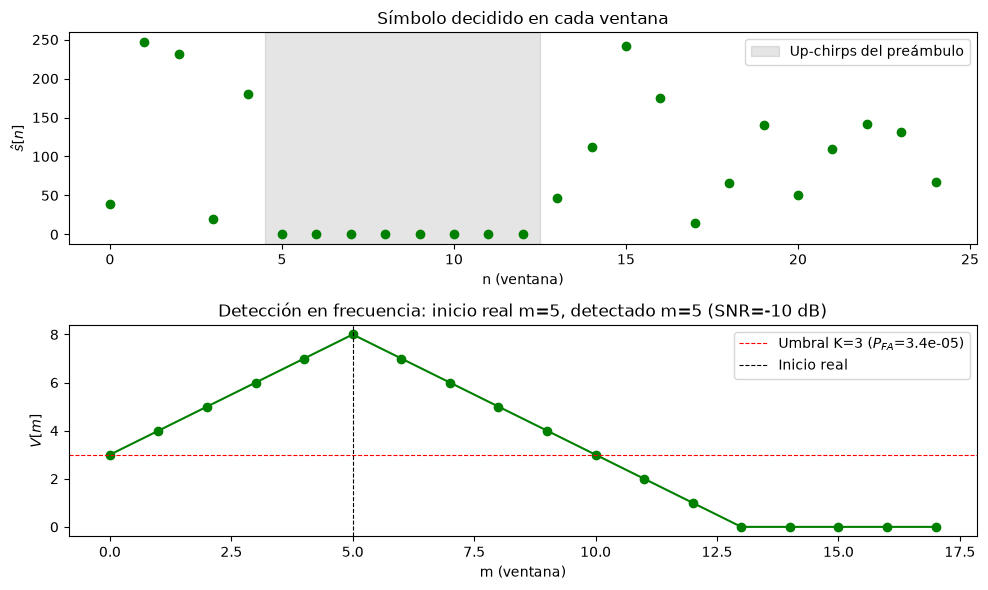

In [17]:
# Detección en frecuencia sobre el escenario
K = detection.threshold("freq", p, noise_power, P_FA)
V = detection.preamble_zero_count(r, p)
start = detection.detect_start(V, K, p.n_upchirps)

# Símbolo decidido en cada ventana, para ver qué ventanas cuentan en V[m]
symbols_rx = rx.demodulator(r[: r.size // p.M * p.M], p)

plots.freq_detection(symbols_rx, V, K, start, gap, p, P_FA, SNR_dB);

#### Performance en canal selectivo en frecuencia

Se estima la probabilidad de detectar el inicio correcto en función del SNR, en el canal selectivo y en el plano como referencia.

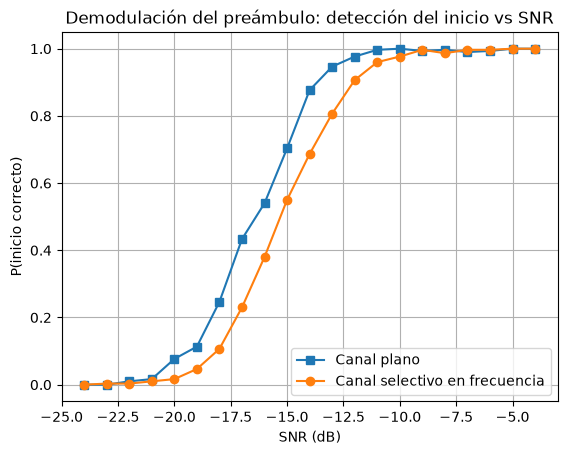

In [18]:
# Inicio correcto y FER en el canal plano y en el selectivo en frecuencia
start_flat["freq"], _ = simulation.frame_rates(
    detection.detect_freq,
    SNRs_rates_dB,
    channel.FLAT,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)
start_sel["freq"], _ = simulation.frame_rates(
    detection.detect_freq,
    SNRs_rates_dB,
    channel.FREQ_SELECTIVE,
    p,
    P_FA,
    simulations,
    num_symbols=num_symbols,
    gap=gap,
)

plots.start_vs_snr(
    SNRs_rates_dB,
    start_flat["freq"],
    start_sel["freq"],
    "Demodulación del preámbulo: detección del inicio vs SNR",
);

**Observaciones**:
- En el canal plano el inicio se encuentra en la mitad de las tramas cerca de $-16.5$ dB: cada ventana decide con el SNR de un solo símbolo.
- No llega al 100 % ni a SNR alto, por los empates descriptos arriba ($\approx 0.4\%$).
- El canal selectivo cuesta $\approx 1$ dB: el eco agrega a cada ventana una muestra del símbolo anterior, y solo el camino principal aporta al pico del bin 0.

### Comparación de los métodos

#### Detección del inicio

Se superponen las curvas de inicio correcto de los tres métodos: línea llena para el canal plano y punteada para el selectivo en frecuencia. Junto con la ROC, es la métrica para comparar los detectores: $1 - P(\text{inicio correcto})$ es exactamente la fracción de tramas que se pierden por la detección o la sincronización, ya que en esta simulación un inicio corrido una sola muestra invalida el *payload*.

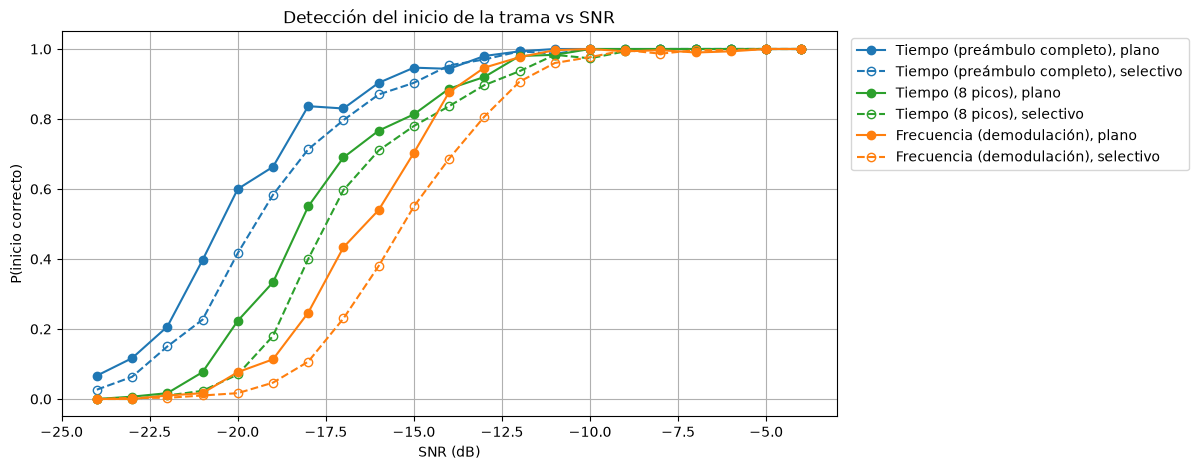

In [19]:
plots.compare_methods(
    SNRs_rates_dB,
    start_flat,
    start_sel,
    "P(inicio correcto)",
    "Detección del inicio de la trama vs SNR",
);

**Observaciones**:
- Orden de los métodos, en ambos canales: correlación con el preámbulo completo, búsqueda de 8 picos y demodulación del preámbulo, con unos 2 dB entre cada uno (50 % de aciertos cerca de $-20.5$, $-18.5$ y $-16.5$ dB en el canal plano).
- **Integración coherente contra no coherente**: los dos métodos en el tiempo usan los mismos 8 picos de $y[k]$. Sumarlos antes del módulo (preámbulo completo) gana unos 2 dB frente a sumar sus energías (8 picos), a cambio de necesitar que la fase se mantenga durante el preámbulo.
- **Decisión blanda contra decisión dura**: los métodos en el tiempo conservan cuánto se parece cada posición a un *up-chirp*. La demodulación reduce cada ventana a "símbolo 0 o no", perdiendo información, y además necesita sincronía de símbolo.
- El canal selectivo desplaza todas las curvas $\approx 1$ dB sin cambiar el orden: solo el camino principal aporta a los picos.

#### Falsas alarmas

En las curvas de inicio correcto el silencio antes de la trama es corto y las falsas alarmas casi no penalizan, pero un receptor real pasa la mayor parte del tiempo escuchando solo ruido. Para validar que los umbrales de Neyman-Pearson cumplen la $P_{FA}$ pedida, se aplica cada método a una señal larga de solo ruido (20000 símbolos) y se mide la fracción de posiciones que superan el umbral.

En el punto de operación la $P_{FA}$ por muestra de los métodos en el tiempo es $\approx 1.3 \cdot 10^{-7}$: harían falta $\sim 10^9$ muestras para observar suficientes falsas alarmas. La distribución bajo $H_0$ es la misma para cualquier umbral, así que se valida el cálculo del umbral en un rango de $P_{FA}$ que se puede medir, de $10^{-1}$ a $10^{-5}$ por posición. En frecuencia solo se pueden medir los umbrales $K = 1$ y $K = 2$: $P_{FA}(3) \approx 3.3 \cdot 10^{-6}$ daría menos de una falsa alarma esperada en 20000 ventanas.

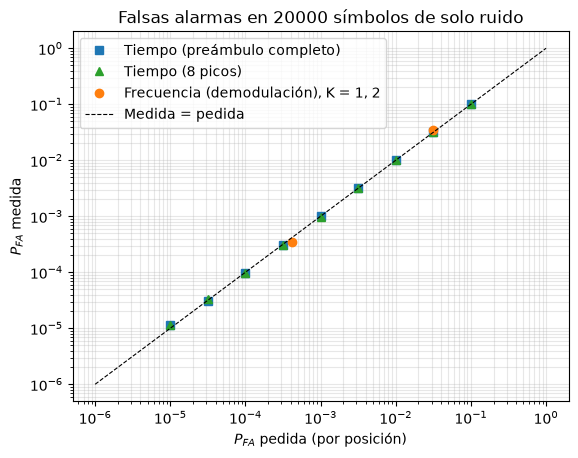

In [20]:
# Señal de solo ruido de 20000 símbolos, con la potencia de ruido de -10 dB
num_noise_symbols = 20000
P_FA_targets = np.logspace(-1, -5, 9)  # P_FA pedidas, por posición
Ks = (1, 2)  # Umbrales medibles en frecuencia

false_alarms = simulation.measured_false_alarms(p, num_noise_symbols, P_FA_targets, Ks)
plots.false_alarms(false_alarms, num_noise_symbols, Ks);

**Observaciones**:
- Los tres métodos cumplen la $P_{FA}$ pedida: los puntos caen sobre la diagonal en todo el rango medible. Esto valida las distribuciones bajo $H_0$ (exponencial, Erlang y binomial) y el cálculo de los umbrales, y respalda usar la $P_{FA}$ teórica en el punto de operación y en la ROC, aunque estén fuera del rango medible.
- En $10^{-5}$ por posición la medición se dispersa: hay pocas falsas alarmas ($\approx 50$ esperadas) y llegan agrupadas. La plantilla es periódica cada $2^{SF}/2$ muestras, así que el estadístico en posiciones separadas medio símbolo usa casi las mismas muestras de ruido, y una falsa alarma suele repetirse en las posiciones vecinas.

#### Curva ROC

Las curvas de inicio correcto evalúan si se encuentra el inicio, lo que mezcla detección y localización. Para comparar los métodos solo como detectores se usa el test binario en una posición (una muestra en el tiempo, una ventana en frecuencia):

- $H_0$: los 8 símbolos a partir de la posición contienen solo ruido.
- $H_1$: la posición está alineada con el inicio del preámbulo.

Cada umbral define un punto de operación ($P_{FA}$, $P_D$) con $P_{FA} = P(\text{'}H_1\text{'} \mid H_0)$ y $P_D = P(\text{'}H_1\text{'} \mid H_1)$. La curva ROC (*Receiver Operating Characteristic*) recorre todos los umbrales y muestra el compromiso entre ambas probabilidades: subir el umbral reduce las falsas alarmas a costa de perder detecciones. El criterio de Neyman-Pearson elige el punto de la curva con la mayor $P_D$ que respeta la $P_{FA}$ tolerable. Un detector es mejor que otro si su curva queda por encima: para la misma $P_{FA}$, detecta más.

El receptor opera con $P_{FA}$ muy bajas, así que el eje de $P_{FA}$ es logarítmico. Además:

- **$P_{FA}$ por símbolo**: en el tiempo se prueban $2^{SF}$ posiciones por símbolo, así que la tasa de falsas alarmas por símbolo es $2^{SF}$ veces la $P_{FA}$ por muestra. Con este eje las tres curvas se comparan a la misma tasa de falsas alarmas, y los puntos de operación de Neyman-Pearson (estrellas) caen sobre la misma vertical.
- **$P_{FA}$ teórica**: con 2000 realizaciones bajo $H_0$ no se pueden estimar $P_{FA}$ menores que $1/2000$ por posición, y el punto de operación está muy por debajo. Pero bajo $H_0$ la distribución de cada estadístico es conocida (exponencial, Erlang y binomial): para cada $P_{FA}$ se calcula el umbral con las funciones de Neyman-Pearson de cada método, y solo se estima $P_D$, que sí se mide bien con pocas realizaciones. Las curvas empíricas (punteadas) validan las teóricas donde se pueden medir.

El estadístico $V[m]$ de la detección en frecuencia solo toma 9 valores (0 a 8 ventanas), así que su curva es una escalera: entre dos umbrales consecutivos, Neyman-Pearson se queda con el más alto que respeta la $P_{FA}$.

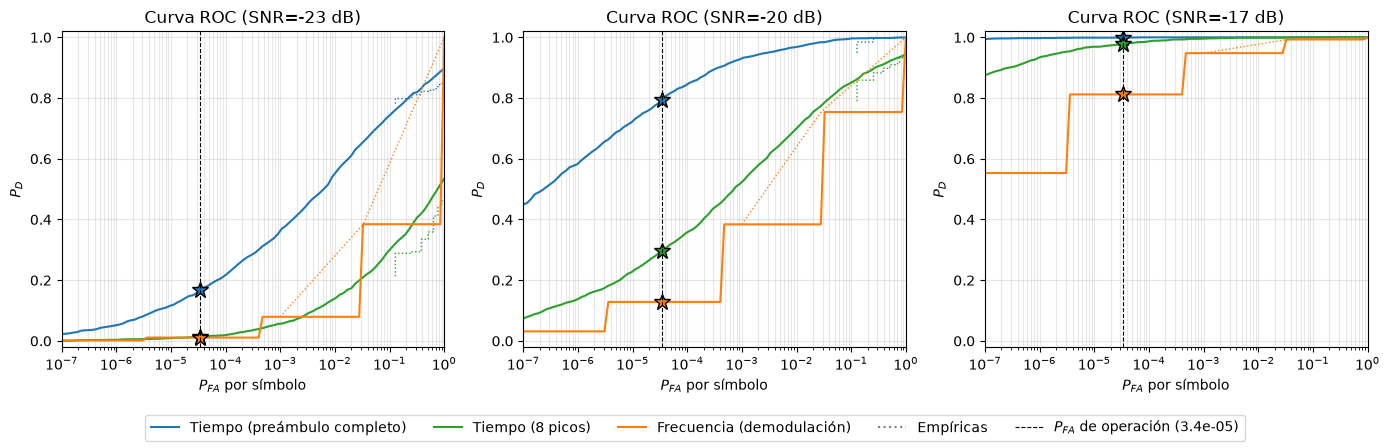

In [21]:
SNRs_roc_dB = [-23.0, -20.0, -17.0]  # Un gráfico por SNR, en el rango donde cambia la detección
simulations_roc = 2000  # Realizaciones por hipótesis
P_FA_axis = np.logspace(-7, 0, 100)  # P_FA por símbolo

roc_curves = {
    SNR: simulation.roc_curves(p, SNR, simulations_roc, P_FA_axis, P_FA) for SNR in SNRs_roc_dB
}
plots.roc(roc_curves, P_FA_axis, P_FA);

**Observaciones**:
- En el punto de operación ($P_{FA} \approx 3.4 \cdot 10^{-5}$ por símbolo, estrellas), a $-20$ dB la correlación con el preámbulo completo detecta con $P_D \approx 0.8$, la búsqueda de 8 picos con $\approx 0.3$ y la demodulación con $\approx 0.14$. A $-17$ dB los métodos en el tiempo ya detectan casi siempre y la demodulación llega a $\approx 0.8$.
- La correlación con el preámbulo completo queda por encima de las demás para cualquier $P_{FA}$ y SNR. Entre la búsqueda de 8 picos y la demodulación el orden depende de la $P_{FA}$: con $P_{FA}$ bajas gana la búsqueda de 8 picos, pero con $P_{FA}$ altas y SNR bajo la demodulación puede superarla. Los métodos en el tiempo prueban $2^{SF}$ posiciones por símbolo y necesitan un umbral más alto para la misma tasa de falsas alarmas; la demodulación prueba una sola, porque asume sincronía de símbolo.
- Bajar la $P_{FA}$ cuesta poco en los métodos en el tiempo: la $P_D$ cae en forma gradual. En la demodulación cae a escalones: con 9 umbrales posibles, la $P_{FA}$ de operación obliga a $K = 3$, con una $P_{FA}$ real unas 10 veces menor que la tolerada.
- Las curvas empíricas (punteadas) coinciden con las teóricas donde se pueden medir: $P_{FA}$ por símbolo mayores que $\approx 0.13$ en el tiempo ($2^{SF}/2000$) y que $\approx 10^{-3}$ en frecuencia.
- El test en una posición funciona a menor SNR que la detección del inicio correcto (a $-20$ dB, $P_D \approx 0.8$ contra $\approx 0.6$ de inicio correcto con la correlación con el preámbulo completo). Encontrar el inicio exige además que la posición correcta supere a las vecinas, que se superponen parcialmente con el preámbulo.

#### Costo computacional

Se mide el tiempo de CPU que necesita cada método para procesar una trama (silencio, preámbulo y 16 símbolos de *payload*): el cálculo del estadístico y la decisión. Los umbrales quedan fuera de la medición, porque se calculan una vez por cada estimación de $\sigma^2$ y no por trama. Cada tiempo es el mínimo de varias mediciones, el menos afectado por otros procesos del sistema.

El costo esperado por muestra recibida, con $M = 2^{SF}$:

- **Preámbulo completo**: correlación directa con una plantilla de $8M$ muestras, $8M$ productos complejos por muestra.
- **8 picos**: correlación con un solo *up-chirp*, $M$ productos por muestra, más 8 sumas.
- **Frecuencia**: un producto por el *down-chirp* y una FFT de $M$ puntos por ventana ($M \log_2 M$ operaciones), $\approx \log_2 M$ operaciones por muestra. Evalúa una posición por ventana en lugar de una por muestra, porque asume sincronía de símbolo.

Los costos de los métodos en el tiempo crecen con $M$, y el de frecuencia casi no: la diferencia aumenta con el SF.

SF   preámbulo completo   8 picos   frecuencia   (veces el tiempo en frecuencia)
 7                   19       4.5            1
 8                   51       8.5            1
 9                  116      17.0            1
10                  212      30.2            1


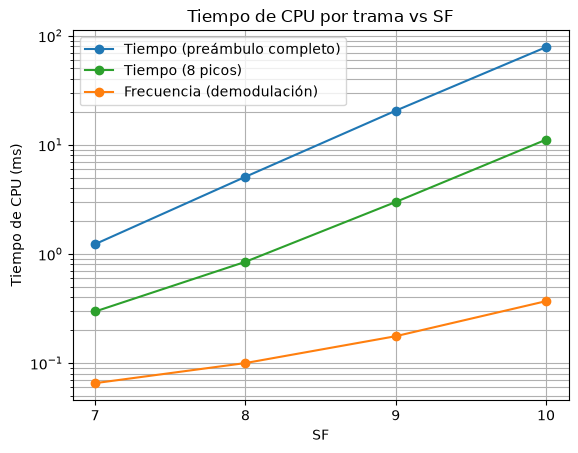

In [22]:
# Tiempo de CPU por trama de cada método, para distintos SF
SFs = list(range(7, 11))  # 7 a 10
cpu = [simulation.methods_cpu_time(LoRaParams(SF=SF, B=p.B), P_FA) for SF in SFs]

# Tiempo de cada método relativo a la demodulación del preámbulo, el más rápido
print("SF   preámbulo completo   8 picos   frecuencia   (veces el tiempo en frecuencia)")
for SF, t in zip(SFs, cpu):
    print(f"{SF:2d}   {t['full'] / t['freq']:18.0f}   {t['peaks'] / t['freq']:7.1f}   {1:10.0f}")

plots.cpu_times(SFs, cpu);

**Observaciones**:
- La demodulación del preámbulo es la más barata en todos los SF: unas 4 veces más rápida que la búsqueda de 8 picos y unas 20 veces más rápida que la correlación con el preámbulo completo con $SF = 7$. Las diferencias crecen con el SF: con $SF = 10$ son unas 35 y 200 veces.
- La trama tiene $\approx 31 M$ muestras, así que el costo por trama de los métodos en el tiempo crece como $M^2$: $\times 4$ por cada SF, como se ve en la pendiente de sus curvas. El de frecuencia crece como $M \log_2 M$, apenas más que $\times 2$ por cada SF.
- La correlación con el preámbulo completo hace 8 veces más productos por muestra que la búsqueda de 8 picos, pero tarda entre 4.5 y 6 veces más, no 8: el tiempo medido incluye operaciones que no dependen del largo de la plantilla (el módulo, la suma de los 8 picos en la búsqueda de picos, la búsqueda del máximo).
- Es el compromiso entre performance y costo: el método que detecta a menor SNR es el más caro. `np.correlate` calcula la correlación en forma directa; con una correlación por FFT (*overlap-save*) los métodos en el tiempo bajarían a $O(\log M)$ operaciones por muestra, aunque seguirían evaluando todas las muestras en lugar de una por ventana.

#### Frame Error Rate (FER)

El FER mide el sistema completo: una trama se pierde si falla la detección del preámbulo o la demodulación del *payload*. Por eso no sirve para comparar los detectores entre sí, sino para responder otra pregunta: ¿la detección limita al sistema?

El ruido del preámbulo y el del *payload* son independientes (muestras disjuntas), así que, con $FER_{ideal}$ el FER con el inicio conocido (solo errores de demodulación):

$$
FER = 1 - P(\text{inicio correcto})\,(1 - FER_{ideal})
\qquad\Rightarrow\qquad
FER - FER_{ideal} = \left(1 - P(\text{inicio correcto})\right)(1 - FER_{ideal})
$$

La diferencia con la detección ideal solo cuenta las fallas de detección en tramas cuyo *payload* se habría decodificado bien: subestima las fallas de detección, y donde el *payload* falla igual ($FER_{ideal} \approx 1$) las oculta por completo. La cantidad de tramas perdidas por la detección es $1 - P(\text{inicio correcto})$, de la sección anterior.

Se compara el FER de los tres métodos con el de la detección ideal, en el canal plano (línea llena) y en el selectivo en frecuencia (punteada).

El FER cae varios órdenes de magnitud en pocos dB, así que el eje es logarítmico. Para medir FER chicos hacen falta muchas tramas, pero donde el FER es alto alcanzan pocas: cada SNR se simula hasta juntar 30 tramas con error, con un máximo de 2000 tramas. El FER más chico que se puede medir es $1/2000 = 5 \cdot 10^{-4}$; los puntos sin errores ($FER = 0$) no se dibujan.

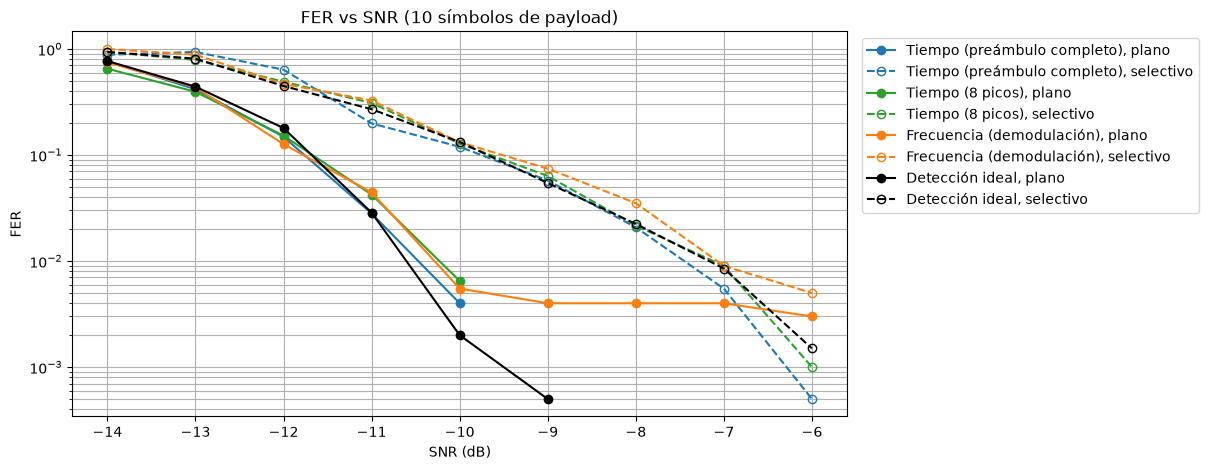

In [23]:
# Cada SNR termina al juntar 30 tramas con error, o a las 2000 tramas
SNRs_fer_dB = np.arange(-14.0, -5.0, 1.0)  # -14 a -6 dB
detectors = {
    "full": detection.detect_full,
    "peaks": detection.detect_peaks,
    "freq": detection.detect_freq,
    "ideal": detection.ideal_detector(gap),  # Referencia: solo hay errores de demodulación
}

fer_flat, fer_sel = {}, {}
for method, detect in detectors.items():
    for fer, h in ((fer_flat, channel.FLAT), (fer_sel, channel.FREQ_SELECTIVE)):
        _, fer[method] = simulation.frame_rates(
            detect, SNRs_fer_dB, h, p, P_FA, 2000, num_symbols=num_symbols, gap=gap, min_errors=30
        )

plots.compare_methods(
    SNRs_fer_dB,
    fer_flat,
    fer_sel,
    "FER",
    f"FER vs SNR ({num_symbols} símbolos de payload)",
    logy=True,
);

**Observaciones**:
- En el canal plano la detección no limita al sistema: las curvas de los métodos en el tiempo coinciden con la de detección ideal dentro del error de la simulación. El FER lo pone el *payload*: $\approx 2 \cdot 10^{-3}$ a $-10$ dB y por debajo de lo medible ($5 \cdot 10^{-4}$) desde $-9$ dB.
- La escala logarítmica muestra lo que la lineal escondía: la demodulación del preámbulo tiene un piso de $\approx 4 \cdot 10^{-3}$ desde $-10$ dB. Son los empates descriptos en la detección en frecuencia ($2^{-SF} \approx 0.4\%$), que no bajan con el SNR. Es el único detector que limita al sistema a SNR alto.
- Por debajo de $-11$ dB el *payload* falla igual y oculta las fallas de detección, aunque los métodos difieren en hasta 4 dB en la detección del inicio.
- El canal selectivo empeora mucho el FER, también con detección ideal: $\approx 0.13$ a $-10$ dB contra $2 \cdot 10^{-3}$ en el plano, y la curva cae más lento (una década cada $\approx 2$ dB, contra una por dB). El eco no se comporta como ruido: después del *down-chirp* concentra el 20 % de la potencia en el bin $s - 2$, un competidor fijo del bin del símbolo. Al ruido le alcanza con acercar esos dos bins, en lugar de levantar un bin vacío.
- El preámbulo es más robusto que el *payload* porque la detección acumula información de 8 símbolos, mientras que el *payload* exige que todos sus símbolos se decidan bien.